# Hotel Booking Cancellation Prediction


## 1. Project objective

The objective is to investigate historical hotel booking data and build a
machine learning model that estimates cancellation risk.

## 2. Business question

Can information available when a booking is created help us estimate
whether that booking will eventually be cancelled?

## 3. Dataset

- Source: TidyTuesday, 11 February 2020
- Original research: Antonio, Almeida, and Nunes (2019)
- Target: `is_canceled`
- Prediction point: booking creation

## 4. Data Preparation

- Download the data, read it with pandas
- Look at the data
- Make column names and values look uniform
- Check if all the columns ready correctly
- Check if the `is_canceled` needs any preparation

In [217]:
# !git clone https://github.com/nabila-natasha/hotel-booking-cancellation-ml.git
# %cd hotel-booking-cancellation-ml/notebooks

In [218]:
from pathlib import Path
from urllib.request import urlretrieve

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [219]:
URL = 'https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2020/2020-02-11/hotels.csv'
RAW_PATH = Path("../data/raw/hotels.csv")
PROCESSED_PATH = Path("../data/processed/hotels_clean.csv")

In [220]:
RAW_PATH.parent.mkdir(parents=True, exist_ok=True)
PROCESSED_PATH.parent.mkdir(parents=True, exist_ok=True)

if not RAW_PATH.exists():
  urlretrieve(URL, RAW_PATH)

In [221]:
df = pd.read_csv(RAW_PATH)
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [222]:
df.dtypes

,0
hotel,object
is_canceled,int64
lead_time,int64
arrival_date_year,int64
arrival_date_month,object
arrival_date_week_number,int64
arrival_date_day_of_month,int64
stays_in_weekend_nights,int64
stays_in_week_nights,int64
adults,int64


In [223]:
categorical_columns = list(df.dtypes[df.dtypes == 'object'].index)

for c in categorical_columns:
    df[c] = df[c].str.lower().str.replace(' ', '_')

In [224]:
df.head().T

,0,1,2,3,4
hotel,resort_hotel,resort_hotel,resort_hotel,resort_hotel,resort_hotel
is_canceled,0,0,0,0,0
lead_time,342,737,7,13,14
arrival_date_year,2015,2015,2015,2015,2015
arrival_date_month,july,july,july,july,july
arrival_date_week_number,27,27,27,27,27
arrival_date_day_of_month,1,1,1,1,1
stays_in_weekend_nights,0,0,0,0,0
stays_in_week_nights,0,0,1,1,2
adults,2,2,1,1,2


## 5. EDA

- Target (cancellation rate)
- Leakage and post-booking columns check
- Duplicates check
- Missing values check
- Invalid and extreme values

### 5.1 Target (Cancellation Rate on Raw Data)

In [225]:
print("Cancelation rate on raw data:", df['is_canceled'].mean().round(4))

Cancelation rate on raw data: 0.3704


### 5.2 Leakage Audit

Data leakage means the model gets to see information it wouldn’t have in real life. Our model should predict, at the moment someone makes a booking, “will this be cancelled?” Anything recorded later, or anything that is just the answer in disguise, is cheating.

1) Timing test: what do the `reservation_status` and `reservation_status_date` say about the booking outcome `is_canceled`?

**Result**:  
Every “canceled” row has `is_canceled = 1`. Every “check-out” row has `is_canceled = 0`. A “no-show” counts as cancelled too. So `reservation_status` is the target written in different words, and drop it.

In [226]:
pd.crosstab(df['reservation_status'], df['is_canceled'], margins=True)

is_canceled,0,1,All
reservation_status,,,
canceled,0,43017,43017
check-out,75166,0,75166
no-show,0,1207,1207
All,75166,44224,119390


`reservation_status_date`: for cancelled bookings it is the cancellation date

In [227]:
df.groupby('reservation_status')['reservation_status_date'].agg(['min', 'max'])

,min,max
reservation_status,,
canceled,2014-10-17,2017-08-26
check-out,2015-07-01,2017-09-14
no-show,2015-07-02,2017-08-31


2) Empirical check: how well does ONE column alone predict the target?
   - AUC is a score for how well a column can separate cancelled from not cancelled
   - A tiny tree on each column; a suspiciously high AUC flags leakage.

In [228]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_val_score

**Result**:  
- `reservation_status` scored 1.000, a perfect score from one column. That is a red flag, and it matches the crosstab.
- Everything else scored 0.57 to 0.70, which is normal. Columns like `country`, `lead_time` and `deposit_type` help a bit but don’t give away the answer.
- `reservation_status_date` scored only 0.660 which looks innocent. But for cancelled bookings, that date is when the cancellation happened and the hotel only knows it afterward. It fails the timing check, so drop it.

In [229]:
def single_feature_auc(df, target="is_canceled", sample=30000, seed=42):
    d = df.sample(min(sample, len(df)), random_state=seed)
    y = d[target]
    rows = []
    for col in d.columns.drop(target):
        x = d[[col]].copy()

        if x[col].dtype == "object":
            x[col] = x[col].astype("category").cat.codes   # convert text-based categorical columns into numerical integers (label encoding)
        x = x.fillna(-1) # fill missing values with -1
        auc = cross_val_score(DecisionTreeClassifier(max_depth=5, random_state=seed), x, y, cv=3, scoring="roc_auc").mean()
        rows.append((col, round(auc, 3)))

    return pd.DataFrame(rows, columns=["column", "single_feature_auc"]).sort_values(
        "single_feature_auc", ascending=False)

single_feature_auc(df).head(12)

,column,single_feature_auc
29,reservation_status,1.000
12,country,0.696
1,lead_time,0.691
21,deposit_type,0.665
30,reservation_status_date,0.660
13,market_segment,0.641
28,total_of_special_requests,0.634
22,agent,0.624
26,adr,0.605
19,assigned_room_type,0.605


3) Post-booking suspects: `booking_changes` happens after booking. If the model uses this column, it is peeking into the future, so drop it.

In [230]:
df.groupby('is_canceled')['booking_changes'].describe()

,count,mean,std,min,25%,50%,75%,max
is_canceled,,,,,,,,
0,75166.0,0.293364,0.736266,0.0,0.0,0.0,0.0,21.0
1,44224.0,0.098340,0.451008,0.0,0.0,0.0,0.0,16.0


**Result**:  
18.8% (roughly 95 out of 100 bookings) with different assigned room were not cancelled. The hotel assigns rooms close to arrival, so cancelled guest mostly never gets one. Different room means the guest probably showed up. The hotel knows `assigned_room_type` after the booking is made, so drop it.

In [231]:
pd.crosstab(df['reserved_room_type'] != df['assigned_room_type'], df['is_canceled'], normalize="index").round(3)

is_canceled,0,1
row_0,,
False,0.584,0.416
True,0.946,0.054


4) Counterintuitive but legitimate: the hotel knows the `deposit_type` when booking is made, so it is not leakage.

In [232]:
pd.crosstab(df['deposit_type'], df['is_canceled'], normalize="index").round(3)

is_canceled,0,1
deposit_type,,
no_deposit,0.716,0.284
non_refund,0.006,0.994
refundable,0.778,0.222


### Drop the leaky and post-booking columns:

- `reservation_status`
- `reservation_status_date`
- `booking_changes`
- `assigned_room_type`

In [233]:
LEAKY = ['reservation_status', 'reservation_status_date']
POST_BOOKING = ['booking_changes', 'assigned_room_type']

df_clean = df.drop(columns=LEAKY + POST_BOOKING)

### 5.3 Duplicates Audit

In [234]:
# Count extra occurences of exact duplicate rows

print("Exact duplicates (all columns, as before):", int(df.duplicated().sum()))
print("Exact duplicates (after dropping 4 columns):", int(df_clean.duplicated().sum()))

Exact duplicates (all columns, as before): 31994
Exact duplicates (after dropping 4 columns): 34050


1) Conflicting labels check - two rows with identical deails (same `hotel`, `lead_time`, `country`, `price` and so on) but different labels (one cancelled, one not cancelled) are a conflict. The check is a sanity test on the data for two reasons:  
    - It tells how much **noise** there is. If identical-lloking bookings end differently, no model can get both right, because it has nothing to tell them apart. A big number means a low ceiling on achievable acciracy. A small number means the data is fairly consistent.
    - It helps **judge the duplicates**. If many duplicate groups had conflicting labels, the "duplicates" are probably separate real bookings and dropping them would be questionable. If conflicts are rare, tha doesn't prove anything either way, but it does show they aren't a big problem.

**Result**:  
- The data forms 85,039 groups of identical bookings (many groups contain just one row).
- Only 301 of those groups contain both a cancelled and a not-cancelled booking. That is about 0.35% of groups.

In [235]:
feature_cols = [c for c in df_clean.columns if c != 'is_canceled']

# Same features but different labels = genuinely ambiguous rows
labels_per_group = df_clean.groupby(feature_cols, dropna=False)["is_canceled"].nunique()

print("Total feature groups:", len(labels_per_group))
print("Feature groups with conflicting labels:", (labels_per_group > 1).sum())

Total feature groups: 85039
Feature groups with conflicting labels: 301


### Drop duplicate rows

- The duplicates hurt the evaluation. If a copy lands in training and its twin in the tesset, the model has "seen the answer" and the score looks better than it really is.

In [236]:
print("Rows before:", len(df_clean))

df_clean = df_clean.drop_duplicates()
print("Rows after:", len(df_clean))

Rows before: 119390
Rows after: 85340


### 5.4 Missing Values Audit


**Rules of thumb:**

| Situation | What to do |
|---|---|
| Missing means “does not apply” | Fill with a label (categorical) or 0 (numeric), optionally with a flag |
| Only a handful of rows | Fill with a simple value, or drop those few rows |
| Very high missing % (above ~90%) | Keep a flag, drop the original column |
| Missing in a real numeric column with no special meaning | Fill with the median, plus a flag if the rate is high. Do this inside the modelling pipeline |
| Large share of rows missing | **Never drop the rows** |

In [237]:
missing_summary = pd.DataFrame({
    'missing_count': df_clean.isna().sum(),
    'missing_pct': df_clean.isna().mean().mul(100)
})

missing_summary = missing_summary[missing_summary['missing_count'] > 0].sort_values('missing_pct', ascending=False).round(2)

missing_summary

,missing_count,missing_pct
company,80361,94.17
agent,11729,13.74
country,450,0.53
children,4,0.00


In [238]:
# Is missing agent connected to a particular market segment?

pd.crosstab(df_clean['agent'].isna(), df_clean['market_segment'], normalize="index").round(3)

market_segment,aviation,complementary,corporate,direct,groups,offline_ta/to,online_ta,undefined
agent,,,,,,,,
False,0.000,0.001,0.007,0.084,0.038,0.179,0.691,0.0
True,0.017,0.050,0.305,0.471,0.115,0.013,0.028,0.0


In [239]:
# Cancellation rate when the value is missing vs present

for col in ["company", "agent", "country"]:
    print()
    print(df_clean.groupby(df_clean[col].isna())["is_canceled"].mean().round(3))


company
False    0.111
True     0.287
Name: is_canceled, dtype: float64

agent
False    0.300
True     0.127
Name: is_canceled, dtype: float64

country
False    0.278
True     0.073
Name: is_canceled, dtype: float64


### Handling Missing Values

| Column | Evidence | Reading | Decision |
|---|---|---|---|
| `company` | 94% missing. Cancellation rate: 28.7% if missing vs. 11.1% if present. | Companies cancel less, so “has a company” is informative. | Create a `has_company` flag (0/1), then drop the raw ID (only 4,979 rows have one, spread over many IDs). |
| `agent` | 13.7% missing. Missing rows are mostly direct (47%) and corporate (31%), with only 3% online_ta. Cancellation rate: 12.7% vs. 30.0%. | Missing most likely means “booked without an agency.” | Fill with `0` (safe because the smallest real agent ID is 1), and convert it to **text** so the model treats it as a label. |
| `country` | 0.5% missing (450 rows). Cancellation rate: 7.3% if missing vs. 27.8% if present. | Unknown country behaves differently, so preserve that information. | Fill with `"unknown"`. The sample is small, so don't overinterpret the 7.3% cancellation rate. |
| `children` | 4 rows have missing values. | Negligible proportion of the dataset. | Fill missing values with `0`, documenting this as an assumption. |



In [240]:
df_clean['has_company'] = df_clean['company'].notna().astype(int)  # 1 = a company is listed
df_clean = df_clean.drop(columns=['company'])

In [241]:
df_clean['agent'] = df_clean['agent'].fillna(0).astype(int).astype(str)

In [242]:
df_clean['country'] = df_clean['country'].fillna('unknown')

In [243]:
df_clean['children'] = df_clean['children'].fillna(0)

### 5.5 Invalid and  Extreme Values

In [244]:
df_clean.describe().T

,count,mean,std,min,25%,50%,75%,max
is_canceled,85340.0,0.276506,0.447272,0.00,0.00,0.0,1.0,1.0
lead_time,85340.0,78.711870,84.980503,0.00,11.00,48.0,123.0,737.0
arrival_date_year,85340.0,2016.217049,0.683591,2015.00,2016.00,2016.0,2017.0,2017.0
arrival_date_week_number,85340.0,26.776307,13.668068,1.00,16.00,27.0,37.0,53.0
arrival_date_day_of_month,85340.0,15.800621,8.842241,1.00,8.00,16.0,23.0,31.0
stays_in_weekend_nights,85340.0,1.011062,1.034152,0.00,0.00,1.0,2.0,19.0
stays_in_week_nights,85340.0,2.633982,2.061298,0.00,1.00,2.0,4.0,50.0
adults,85340.0,1.880267,0.628039,0.00,2.00,2.0,2.0,55.0
children,85340.0,0.141294,0.459905,0.00,0.00,0.0,0.0,10.0
babies,85340.0,0.011062,0.114844,0.00,0.00,0.0,0.0,10.0


1) Negative `adr` (average daily rate) - A negative price is an error, so drop that row.

In [245]:
print("Negative price:",int((df_clean['adr'] < 0).sum()))

Negative price: 1


2) `adr` = 0
- 1,740 rows (2%). 629 are complementary and other are spread across normal segments. Cancel rate is 10.5%.
- Many look like free or complementary stays and 2% is small. Keep the rows.

In [246]:
print("Zero price:", int((df_clean['adr'] == 0).sum()))

zero_adr = df_clean[df_clean['adr'] == 0]
print(f"\nZero adr by {zero_adr['market_segment'].value_counts()}")

print("\nCancel rate when adr = 0:", zero_adr['is_canceled'].mean().round(3))

Zero price: 1740

Zero adr by market_segment
complementary    629
online_ta        348
offline_ta/to    251
direct           224
groups           209
corporate         74
aviation           5
Name: count, dtype: int64

Cancel rate when adr = 0: 0.105


3) `adr` = 5400
- The next-highest values are `510`, `508`, `451.5`. `5400` sits far from everything else, so it is most likely a typo.
- Drop `adr` = 5400 but keep the 450-510 rows, which are hugh but plausible (suites, peak season).

In [247]:
df_clean['adr'].nlargest(5)

,adr
48515,5400.0
111403,510.0
15083,508.0
103912,451.5
13142,450.0


4) Zero guests (`adults` + `children` + `babies` = 0) - Drop. A booking with nobody is invalid.

In [248]:
print(f"Zero guests: {int((df_clean['adults'] + df_clean['children'] + df_clean['babies'] == 0).sum())}")

Zero guests: 163


5) Extreme guest counts (`adults` max 55, `children` max 10, `babies` max 10) - Drop rows with adults > 10, children > 5 or babies > 5

In [249]:
df_clean['adults'].value_counts().sort_index().tail(10)

,count
adults,
4,59
5,2
6,1
10,1
20,2
26,5
27,2
40,1
50,1


In [250]:
df_clean['children'].value_counts().sort_index().tail(10)

,count
children,
0.0,77019
1.0,4667
2.0,3578
3.0,75
10.0,1


In [251]:
df_clean['babies'].value_counts().sort_index().tail(10)

,count
babies,
0,84428
1,895
2,15
9,1
10,1


6) Zero nights - 639 rows. Drop. A nightly-rate booking with no nights is hard to justify.



In [252]:
print(f"Zero nights: {int((df_clean['stays_in_week_nights'] + df_clean['stays_in_weekend_nights'] == 0).sum())}")

Zero nights: 639


In [253]:
df_clean.columns

Index(['hotel', 'is_canceled', 'lead_time', 'arrival_date_year',
       'arrival_date_month', 'arrival_date_week_number',
       'arrival_date_day_of_month', 'stays_in_weekend_nights',
       'stays_in_week_nights', 'adults', 'children', 'babies', 'meal',
       'country', 'market_segment', 'distribution_channel',
       'is_repeated_guest', 'previous_cancellations',
       'previous_bookings_not_canceled', 'reserved_room_type', 'deposit_type',
       'agent', 'days_in_waiting_list', 'customer_type', 'adr',
       'required_car_parking_spaces', 'total_of_special_requests',
       'has_company'],
      dtype='object')

7) `lead_time` max 737 (about 2 years ahead with 75% of values at or below 123). - Keep. Unsual but possible.

In [254]:
df_clean['lead_time'].describe()

,lead_time
count,85340.000000
mean,78.711870
std,84.980503
min,0.000000
25%,11.000000
50%,48.000000
75%,123.000000
max,737.000000


### Handling invalid and extreme values

| Check | Your evidence | Decision |
|---|---|---|
| Negative `adr` | 1,741 rows have `adr` ≤ 0; 1,740 are exactly zero, meaning only **1 negative value**. | **Drop** (price error). |
| `adr` = 0 | 1,740 rows (2%). Of these, 629 are `complementary` (genuine free stays), and the cancellation rate is only 10.5%. | **Keep**, and mention as a limitation. |
| `adr` = 5400 | The next-highest value is 510, so 5400 is an extreme outlier. | **Drop** (use `adr` ≤ 1000). |
| Zero guests | 163 rows. | **Drop** (a booking with nobody is invalid). |
| Extreme guest counts | Adults 20–55 (12 rows), babies 9–10 (2 rows), and children 10 (1 row), with a clear gap to the next value. | **Drop** rows where adults > 10, children > 5, or babies > 5. |
| Zero nights | 639 rows (0.7%). | **Drop**. A nightly-rate booking with no nights is difficult to justify. |
| `lead_time` max 737 | Booking nearly two years ahead is unusual but possible. | **Keep**. |

In [255]:
n_start = len(df_clean)

total_guests = df_clean['adults'] + df_clean['children'] + df_clean['babies']
total_nights = df_clean['stays_in_week_nights'] + df_clean['stays_in_weekend_nights']

keep = (
    (df_clean['adr'] >= 0) & (df_clean['adr'] <= 1000)
    & (total_guests > 0)
    & (total_nights > 0)
    & (df_clean['adults'] <= 10)
    & (df_clean['children'] <= 5)
    & (df_clean['babies'] <= 5)
)

df_clean = df_clean[keep].reset_index(drop=True)

print("Rows:", n_start, "->", len(df_clean))
print("Missing values left:", int(df_clean.isna().sum().sum()))
print("Cancelation rate:", df_clean['is_canceled'].mean().round(4))

Rows: 85340 -> 84578
Missing values left: 0
Cancelation rate: 0.2784


## 6. EDA on the Clean Data

In [256]:
base_rate = df_clean['is_canceled'].mean() * 100

print(f"Overall cancellation rate: {base_rate:.2f}%")

Overall cancellation rate: 27.84%


### 6.1 Categorical columns (cancellation rate by group)

- Does cancellation behave differently for different kinds of bookings?
- If a group's rate is far from the overall rate, that column carries information the model can use.
- If every group sits near the overall rate, the column probably won't help.

In [257]:
cat_cols_to_check = ['hotel', 'deposit_type', 'market_segment', 'customer_type']

for col in cat_cols_to_check:
  summary = df_clean.groupby(col)['is_canceled'].agg(['count', 'mean'])
  summary.columns = ['bookings', 'cancel_rate']
  print(summary.sort_values('cancel_rate', ascending=False).round(3), '\n')

              bookings  cancel_rate
hotel                              
city_hotel       51724        0.304
resort_hotel     32854        0.238 

              bookings  cancel_rate
deposit_type                       
non_refund         991        0.950
refundable          89        0.292
no_deposit       83498        0.270 

                bookings  cancel_rate
market_segment                       
undefined              2        1.000
online_ta          50881        0.355
groups              4102        0.295
aviation             219        0.196
offline_ta/to      13154        0.150
direct             11532        0.148
complementary        671        0.122
corporate           4017        0.121 

                 bookings  cancel_rate
customer_type                         
transient           70794        0.303
contract             3084        0.165
transient-party     10182        0.154
group                 518        0.079 



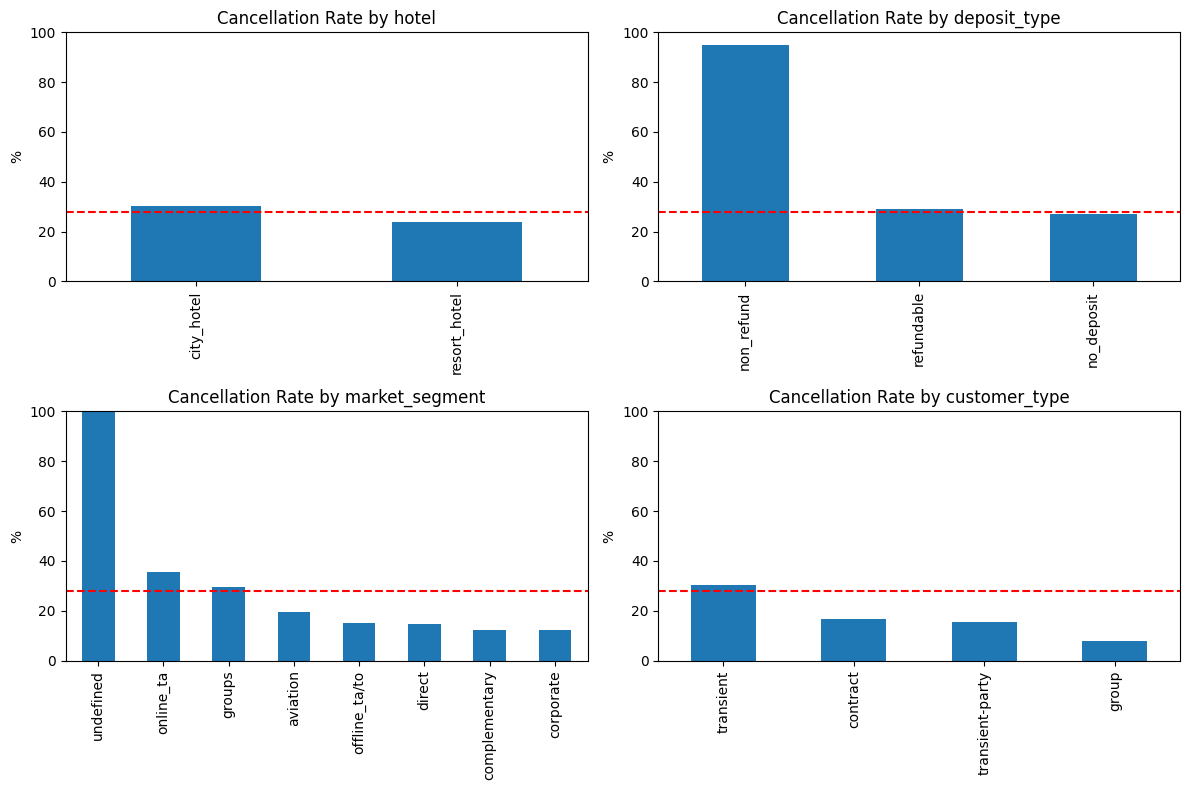

In [258]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, col in zip(axes.flatten(), cat_cols_to_check):
  rate = df_clean.groupby(col)['is_canceled'].mean().sort_values(ascending=False) * 100
  rate.plot(kind="bar", ax=ax, title=f"Cancellation Rate by {col}")
  ax.axhline(base_rate, color="red", linestyle="--")  # red line = overall rate
  ax.set_ylabel("%")
  ax.set_ylim(0, 100)
  ax.set_xlabel("")

plt.tight_layout()
plt.show()

### 6.2 `lead_time` (days between booking and arrival)
 - Does booking further ahead mean a higher chance of cancelling?
 - Compare lead-time category against overall cancellation rate:
    - Above the line: Higher cancellation rate than average
    - Below the line: Lower cancellation than average
    - Near the line: Similar cancellation rate to average

           count   mean
lead_time              
0-7        17644   8.54
8-30       15997  25.58
31-90      22108  32.38
91-180     17744  35.27
181-365    10588  40.76
366+         497  42.86 



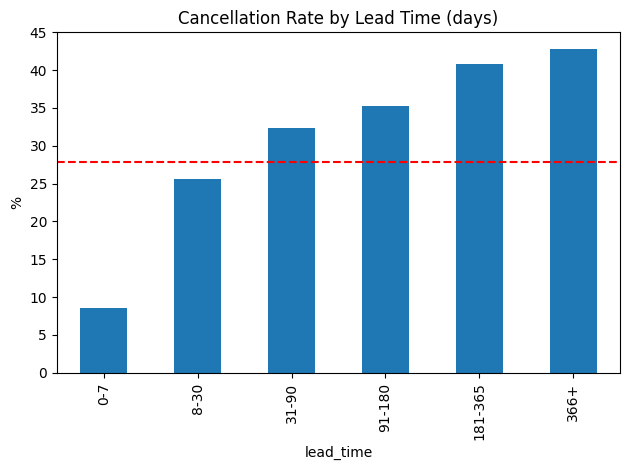

In [259]:
# Binning - dividing continuous numerical data into intervals (group/categories)
# pd.cut() - right inclusive intervals (right boundary included, left boundary excluded)

bins = [-1, 7, 30, 90, 180,365, 1000]  # -1 is intentional, ensure zero included in first interval
labels = ['0-7', '8-30', '31-90', '91-180', '181-365', '366+']
lead_band = pd.cut(df_clean['lead_time'], bins=bins, labels=labels)      # temporary, not added to df_clean

lead_summary = df_clean.groupby(lead_band, observed=True)['is_canceled'].agg(['count', 'mean'])
lead_summary['mean'] = lead_summary['mean'] * 100
print(lead_summary.round(2), '\n')

lead_summary['mean'].plot(kind="bar", title="Cancellation Rate by Lead Time (days)")
plt.ylabel("%")
plt.axhline(base_rate, color="red", linestyle="--")
plt.tight_layout()
plt.show()

### 6.3 Booking history and special requests

- Understand whether a customer's previous booking behaviour/ booking preferences are associated with their likelihood of cancelling the current booking.
- Numerical variables (with only a few distinct values) treated as categorical / group.

In [260]:
df_clean['previous_cancellations'].value_counts().sort_index()

,count
previous_cancellations,
0,82935
1,1367
2,110
3,61
4,30
5,19
6,17
11,27
13,4


In [261]:
# Cap previous_cancellations at 3 so the table stays short

prev_cancel = df_clean['previous_cancellations'].clip(upper=3)
print(df_clean.groupby(prev_cancel)['is_canceled'].agg(['count', 'mean']).round(3), '\n')

for col in ['total_of_special_requests', 'required_car_parking_spaces', 'is_repeated_guest', 'has_company']:
  print(df_clean.groupby(col)['is_canceled'].agg(['count', 'mean']).round(3), '\n')

                        count   mean
previous_cancellations              
0                       82935  0.271
1                        1367  0.758
2                         110  0.309
3                         166  0.235 

                           count   mean
total_of_special_requests              
0                          41868  0.339
1                          28439  0.226
2                          11633  0.213
3                           2287  0.172
4                            315  0.108
5                             36  0.056 

                             count   mean
required_car_parking_spaces              
0                            77326  0.304
1                             7219  0.000
2                               28  0.000
3                                3  0.000
8                                2  0.000 

                   count   mean
is_repeated_guest              
0                  81449  0.286
1                   3129  0.082 

             count   mean
ha

### 6.4 Country and season

In [262]:
top_countries = df_clean['country'].value_counts().head(10).index
country_summary = df_clean[df_clean['country'].isin(top_countries)].groupby('country')['is_canceled'].agg(['count', 'mean']).sort_values('mean', ascending=False).round(3)

print(country_summary, '\n')

         count   mean
country              
bra       1967  0.367
prt      26041  0.364
ita       2972  0.356
esp       7097  0.260
irl       2957  0.221
deu       5224  0.199
fra       8625  0.199
bel       2057  0.199
gbr      10149  0.193
nld       1883  0.184 



month
january      22.347
february     23.221
march        24.626
april        30.629
may          29.458
june         30.748
july         31.994
august       32.498
september    25.083
october      24.345
november     21.551
december     27.175
Name: is_canceled, dtype: float64 



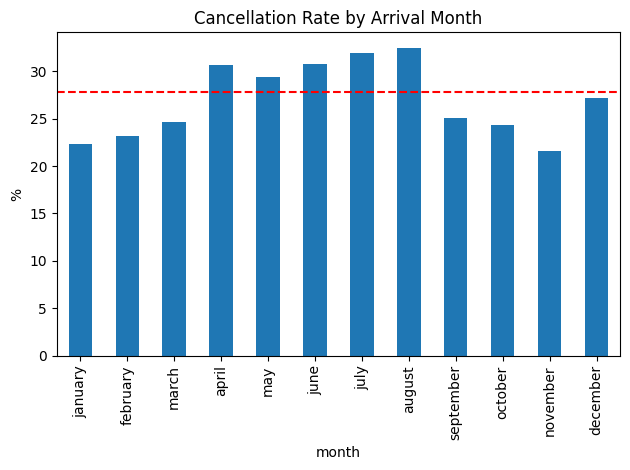

In [263]:
# Check how months are spelled first: df_clean['arrival_date_month'].unique()
month_order = ['january', 'february', 'march', 'april', 'may', 'june', 'july', 'august', 'september', 'october', 'november', 'december']
month_rate = df_clean.assign(month=df_clean['arrival_date_month'].str.lower()).groupby('month')['is_canceled'].mean().reindex(month_order) * 100
print(month_rate.round(3), '\n')

month_rate.plot(kind="bar", title="Cancellation Rate by Arrival Month")
plt.ylabel("%")
plt.axhline(base_rate, color="red", linestyle="--")

plt.tight_layout()
plt.show()

### 6.5 Correlation with the target (numeric columns)

- Correlation measures the strength and direction of a relationship between two variables.
- Correlation coefficient ranges from -1 to +1:
  - +1: when this column rises, cancellation tends to rise
  - 0: no linear relationship between this column and cancellation
  - -1: when this column rises, cancellation tend to decrease

required_car_parking_spaces      -0.188
total_of_special_requests        -0.126
has_company                      -0.093
is_repeated_guest                -0.086
previous_bookings_not_canceled   -0.053
babies                           -0.022
arrival_date_week_number          0.004
arrival_date_day_of_month         0.005
days_in_waiting_list              0.008
previous_cancellations            0.050
stays_in_weekend_nights           0.056
children                          0.066
stays_in_week_nights              0.079
adults                            0.084
arrival_date_year                 0.085
adr                               0.127
lead_time                         0.190
Name: is_canceled, dtype: float64 



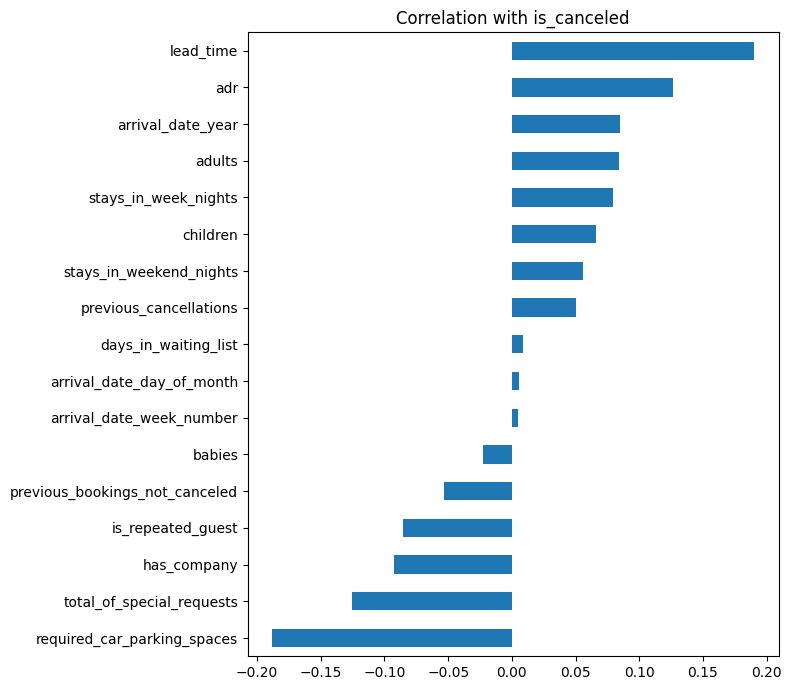

In [264]:
corr = df_clean.corr(numeric_only=True)['is_canceled'].drop('is_canceled').sort_values()
print(corr.round(3), '\n')

corr.plot(kind="barh", figsize=(8, 7), title="Correlation with is_canceled")

plt.tight_layout()
plt.show()

## 7. Feature Importance

- Which columns help predict cancellation?
- Two different methods:
  - **Mutual information**: How much does knowing a column reduce uncertainty about cancellation? A higher score means more informative.
  - **Random forest importance**: builds many decision trees and measures how much each column improved the trees' splits. It reflects what a real model would rely on.

In [265]:
from sklearn.feature_selection import mutual_info_classif

X = df_clean.drop(columns=['is_canceled']).copy()  # create copy to ensure the transformations don't affect original df_clean
y = df_clean['is_canceled']

# Turn text columns into number codes (fine for this quick look, not for the final model)
text_cols = [c for c in X.columns if not pd.api.types.is_numeric_dtype(X[c])]   # check whether the selected column contain non-numerical data
for c in text_cols:
  X[c] = X[c].astype("category").cat.codes

### 7.1 Mutual Information

agent                             0.049919
lead_time                         0.039380
adr                               0.032276
required_car_parking_spaces       0.027536
market_segment                    0.024692
country                           0.022110
deposit_type                      0.013965
total_of_special_requests         0.012779
distribution_channel              0.011755
customer_type                     0.008800
has_company                       0.008406
previous_bookings_not_canceled    0.008161
is_repeated_guest                 0.007898
days_in_waiting_list              0.007206
previous_cancellations            0.005664
arrival_date_year                 0.004593
stays_in_week_nights              0.003828
arrival_date_month                0.003187
stays_in_weekend_nights           0.003166
hotel                             0.002879
adults                            0.002741
babies                            0.002337
meal                              0.002067
arrival_dat

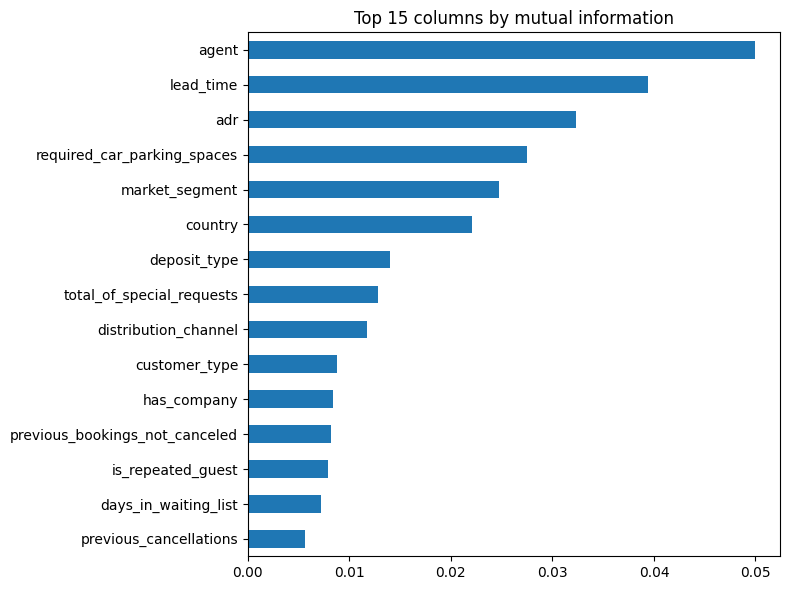

In [266]:
x_sample = X.sample(30000, random_state=42)    # a sample keeps it fast
y_sample = y.loc[x_sample.index]
is_text = [c in text_cols for c in x_sample.columns]

mi = mutual_info_classif(x_sample, y_sample, discrete_features=is_text, random_state=42)
mi_scores = pd.Series(mi, index=x_sample.columns).sort_values(ascending=False)
print(mi_scores, '\n')

mi_scores.head(15).sort_values().plot(kind="barh", figsize=(8, 6), title="Top 15 columns by mutual information")
plt.tight_layout()
plt.show()

### 7.2 Random Forest Importance

lead_time                         0.151955
country                           0.146445
total_of_special_requests         0.121917
market_segment                    0.101880
agent                             0.098691
required_car_parking_spaces       0.085693
deposit_type                      0.050052
previous_cancellations            0.037609
customer_type                     0.035068
adr                               0.032889
arrival_date_year                 0.027829
distribution_channel              0.016351
stays_in_week_nights              0.015977
hotel                             0.013943
arrival_date_week_number          0.012718
previous_bookings_not_canceled    0.009096
arrival_date_month                0.007041
stays_in_weekend_nights           0.006045
arrival_date_day_of_month         0.005619
reserved_room_type                0.004719
adults                            0.004715
meal                              0.004269
children                          0.003730
is_repeated

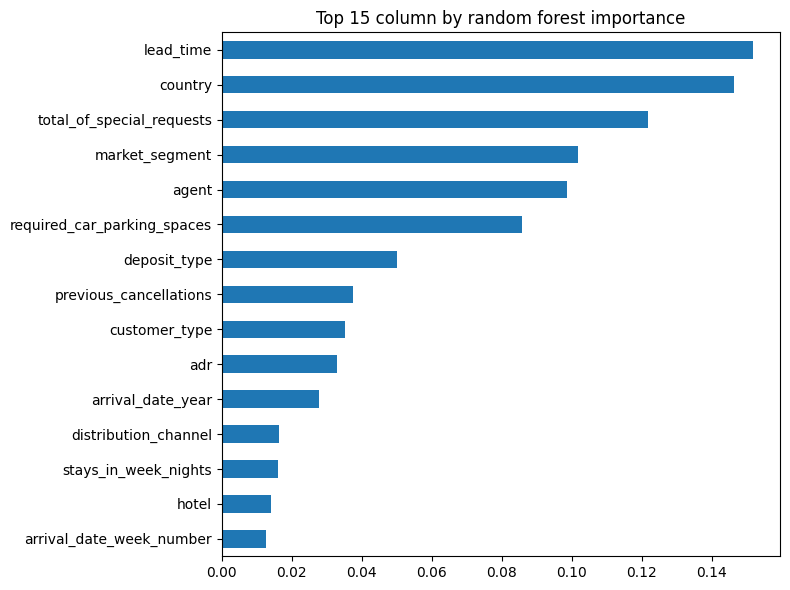

In [267]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=100, max_depth=12, min_samples_leaf=20, n_jobs=-1, random_state=42)
rf.fit(X, y)

rf_scores = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
print(rf_scores, '\n')

rf_scores.head(15).sort_values().plot(kind="barh", figsize=(8, 6), title="Top 15 column by random forest importance")
plt.tight_layout()
plt.show()